# CrusherBayes held out on the ten surveys: the predictive intervals against the CrusherCal band, what the surveys identify and the kill criterion applied as written

**Question:** Does CrusherBayes, the Bayesian calibration of the engine with a structural discrepancy, predict a held-out survey better than the setting-only line and give a sharper, calibrated interval than the CrusherCal band, and does the criterion written before the run keep or drop it?

- **Level:** 4, the product's proposed method
- **Prerequisites:** notebooks 01 and 02 of this topic and notebook 04 of topic 06
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- say what CrusherBayes claims over the single calibrated point of the paper, and what result would drop it, stated before the run;
- score its held-out predictions and 80 percent intervals on the ten surveys against the setting-only line, the backbone, the free-form regression and the CrusherCal band;
- read the contraction table to say which parameters the ten surveys identify and which stay at their prior;
- read the paired comparison that the App's comparison view shows, recompute one of its 95 percent intervals from the held-out predictions, and say how far ten surveys back the recommended method;
- apply the kill criterion from the numbers computed here, compare it with the committed verdict, and say what the convergence record shows.

## Setup

Numpy and matplotlib; the CrusherBayes module is imported for its kill-criterion function, and its sampler is not run here (notebook 02 ran it live).

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader, the backbone builder, the CrusherCal functions, the CrusherBayes module, the paired comparison and the readiness rules.

In [1]:

# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, comparison, loo, crusherbayes as cb
from pipeline.core import readiness
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`, `VERSION`, `data/derived/hp500/crusherbayes.json`, and, for the paired comparison, `data/derived/hp500/comparison.json` with its input `data/derived/hp500/loo.json`. That document holds the ten-fold result of the full-length sampler, eleven posteriors of 7000 steps each, which is baked offline and never run in a notebook; **the CrusherBayes numbers of this notebook are read from it and scored here, and are not a live run**. The CrusherCal band and the comparators are computed live.

The cell reads the surveys, builds CrusherCal's held-out document live and loads the committed one.

In [2]:

# The surveys, the backbone and CrusherCal's held-out document built live, and the committed
# CrusherBayes document; the paired comparison and its CrusherCal input, as the pipeline wrote them
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
crushercal = loo.build(backbone.build(surveys, version), version)
committed = json.loads((ROOT / "data/derived/hp500/crusherbayes.json").read_text(encoding="utf-8"))
paired_doc = json.loads((ROOT / "data/derived/hp500/comparison.json").read_text(encoding="utf-8"))
loo_doc = json.loads((ROOT / "data/derived/hp500/loo.json").read_text(encoding="utf-8"))
record = committed["convergence"]["folds"]
text = (
    'surveys: {} | release label: {} | committed chains: {} steps, '
    'converged {} of {} posteriors'
)
passed = sum(c["converged"] for c in record)
print(text.format(len(surveys), version, committed["method"]["steps"], passed, len(record)))


surveys: 10 | release label: 0.13.000 | committed chains: 7000 steps, converged 11 of 11 posteriors


## Method

**The claim and the rule that tests it.** The calibration of Rocha et al. (2024) is a point fit. CrusherBayes puts a posterior over the engine's eight fitted scalars, adds a low-order structural discrepancy per target (Kennedy and O'Hagan, 2001), and refits it without each held-out survey. The design document states the hypothesis and its kill criterion before the run: the method is dropped as a predictor if (a) its power error is not below the setting-only line's by at least 3 points and its throughput error does not beat the backbone's by the same margin, and (b) on either target its coverage lies outside 0.7 to 0.9 or its band is wider than the CrusherCal band. Three points of MAPE is the margin because at ten surveys a smaller difference is noise. The design document asks for the nested coverage and for the band to be compared at equal coverage; the module reads the coverage as that of CrusherBayes's own posterior interval and the width rule as a direct comparison of the two mean widths, with the coverages reported beside (`cb.kill_criterion`). Here the reading changes nothing, because the two methods have the same coverage on each target, 0.8 on the throughput and 0.9 on the power, as the cells below print. The notebook scores everything the rule needs, then applies the rule.

**CrusherCal's band.** The comparison band is the one the product already ships: the backbone's held-out prediction plus or minus 1.2816 times the nested sigma, in which each survey's sigma comes from the residuals of the other nine (notebook 04 of topic 06). The cell builds it for both targets from the live CrusherCal document.

Written as a formula, with $\Delta_P = \mathrm{MAPE}^{\mathrm{CSS}}_{P} - \mathrm{MAPE}^{\mathrm{CB}}_{P}$ the power gain over the setting-only line (superscript CSS, the line on the closed-side setting; cal is the calibrated backbone and CB CrusherBayes) and $\Delta_Q = \mathrm{MAPE}^{\mathrm{cal}}_{Q} - \mathrm{MAPE}^{\mathrm{CB}}_{Q}$ the throughput gain over the backbone, both in points, $c_t$ the held-out coverage of the 80 percent interval on target $t$, $\bar w_t$ its mean width and $\bar w^{\mathrm{CC}}_t$ the mean width of CrusherCal's nested band,

$$\text{dropped} \iff \underbrace{\bigl(\Delta_P < 3\bigr) \wedge \bigl(\Delta_Q < 3\bigr)}_{\text{(a)}} \;\wedge\; \underbrace{\bigvee_{t \in \{Q, P\}} \Bigl( c_t \notin [0.7,\, 0.9] \;\vee\; \bar w_t > \bar w^{\mathrm{CC}}_t \Bigr)}_{\text{(b)}},$$

so the method survives if it wins on accuracy by the margin on either target, or if its intervals are both calibrated within the window and no wider than the band the product already ships. The rule is `cb.kill_criterion`, and it is fixed before the run, which is what makes its verdict evidence rather than a choice.

In [3]:

# CrusherCal's 80 percent band per survey: the backbone's held-out prediction plus or minus 1.2816
# times the nested sigma
cc_band = {}
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    pred = np.array(strict["pred"]["M0"])
    nested = loo.nested_band_coverage(measured - pred)
    half = loo.band_factor(0.8) * np.array(nested["sigma"])
    cc_band[name] = (pred - half, pred + half)
    outside = (np.flatnonzero(~np.array(nested["covered"])) + 1).tolist()
    print(f"{name:5s} CrusherCal band: coverage {nested['coverage']:.2f}, mean width {np.mean(2 * half):7.1f}, "
          f"surveys outside: {outside}")


tph   CrusherCal band: coverage 0.80, mean width   473.8, surveys outside: [1, 6]
kW    CrusherCal band: coverage 0.90, mean width   209.8, surveys outside: [7]


## Comparison

The next cell scores CrusherBayes on the same footing: the posterior predictive mean of each held-out survey from the committed document against the measurement, the share of surveys inside its own 80 percent interval, and the mean width of that interval.

In [4]:

# CrusherBayes's held-out predictions and 80 percent intervals, from the committed document, scored
# here
cb_score = {}
for name in cb.TARGETS:
    block = committed["loo"][name]
    measured = np.array(block["measured"])
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    inside = (measured >= lo) & (measured <= hi)
    mape = loo.mape(measured, np.array(block["pred_mean"]))
    cb_score[name] = {"mape": mape, "coverage": float(inside.mean()), "width": float(np.mean(hi - lo))}
    outside = (np.flatnonzero(~inside) + 1).tolist()
    print(f"{name:5s} CrusherBayes: MAPE {mape:5.2f} %, coverage {inside.mean():.2f}, "
          f"mean width {np.mean(hi - lo):7.1f}, surveys outside: {outside}")


tph   CrusherBayes: MAPE 12.00 %, coverage 0.80, mean width   439.1, surveys outside: [1, 3]
kW    CrusherBayes: MAPE 14.31 %, coverage 0.90, mean width   117.7, surveys outside: [4]


The table puts the held-out error of CrusherBayes beside the three comparators, which the notebook computes from the live CrusherCal document with the same function, and below it the mean log predictive density of the held-out values, the score the design document lists beside the error, read from the committed document.

The density is scored the way each method predicts. For CrusherBayes the predictive of a held-out survey is a mixture over the $S$ retained posterior samples, each a normal with mean $\mu_{i,s}$ and variance $v_{i,s}$ (engine plus discrepancy, plus noise); for a comparator it is one normal around its point prediction $\hat y_i$ with the nested sigma $\hat\sigma_{-i}$:

$$\mathrm{lpd}^{\mathrm{CB}}_i = \log \frac{1}{S} \sum_{s=1}^{S} \mathcal{N}\bigl(y_i;\, \mu_{i,s},\, v_{i,s}\bigr), \qquad \mathrm{lpd}^{\mathrm{comp}}_i = \log \mathcal{N}\bigl(y_i;\, \hat y_i,\, \hat\sigma_{-i}^2\bigr),$$

and the table reports the mean over the ten surveys, higher being better. A mixture can put mass where several posterior samples disagree, which a single normal cannot, so the two scores are of different constructions, as the text below the table says.

In [5]:

# The held-out MAPE of CrusherBayes and of the comparators on the same ten surveys
comparator_mape = {}
COMPARATORS = {  # key in the committed documents: method name
    "M0": "backbone",
    "B_lin": "setting-only line",
    "M2": "free-form",
}
print(f"{'target':6s} {'CrusherBayes':>12s} {'backbone':>11s} {'setting-only line':>18s} {'free-form':>11s}")
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    row = {m: loo.mape(measured, np.array(strict["pred"][m])) for m in COMPARATORS}
    comparator_mape[name] = row
    print(f"{name:6s} {cb_score[name]['mape']:12.2f} {row['M0']:11.2f} {row['B_lin']:18.2f} {row['M2']:11.2f}")
# The mean log predictive density of the held-out values, read from the committed document (higher is better)
print('mean log predictive density, from the document')
for name in cb.TARGETS:
    own = committed["loo"][name]["scores"]["lpd_mean"]
    lpd = {m: committed["comparators"][name][m]["lpd_mean"] for m in COMPARATORS}
    print(f"{name:6s} {own:12.3f} {lpd['M0']:11.3f} {lpd['B_lin']:18.3f} {lpd['M2']:11.3f}")


target CrusherBayes    backbone  setting-only line   free-form
tph           12.00       12.09              13.67       12.18
kW            14.31       25.94              12.78       14.03
mean log predictive density, from the document
tph          -6.678      -6.896             -6.709      -6.647
kW           -5.346      -5.847             -5.341      -5.399


On the throughput CrusherBayes has an error of 12.00 percent, against 12.09 for the backbone, 12.18 for the free-form regression and 13.67 for the setting-only line: a gain of 0.09 points over the backbone, well inside the 3-point margin below which ten surveys cannot tell methods apart. On the power it has 14.31 percent against 12.78 for the setting-only line, 14.03 for the regression and 25.94 for the backbone. It beats the backbone on power by 11.6 points, which is the discrepancy term doing what the engine alone cannot, but it does not beat the setting-only line: it is 1.53 points behind a line that has no physics and two coefficients. The log predictive density says the same: on the held-out power CrusherBayes scores -5.346 against -5.341 for the setting-only line, -5.399 for the regression and -5.847 for the backbone, level with the line and well ahead of the backbone. That is the claim it does not win, and the notebook reports it as such.

On the throughput the two scores do not rank the methods the same way: by MAPE CrusherBayes is ahead of the free-form regression, 12.00 against 12.18 percent, while by the log predictive density the regression is slightly ahead, -6.647 against -6.678. The density row also compares different constructions: the comparators' density is a plug-in Gaussian with the nested sigma, CrusherBayes's a posterior mixture, so the two are not strictly like for like. The figure draws the intervals: for each survey the grey bar is CrusherCal's 80 percent band, the blue bar is CrusherBayes's, and the red dot is the measurement.

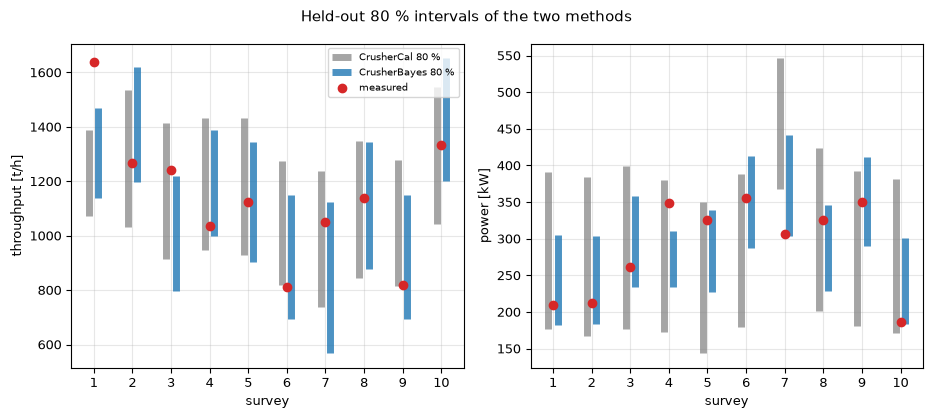

In [6]:

# The ten held-out predictions with the CrusherBayes interval, the CrusherCal band and the measured
# value
x = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2))
for ax, name, ylabel in zip(axes, cb.TARGETS, ('throughput [t/h]', 'power [kW]')):
    block = committed["loo"][name]
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    cc_lo, cc_hi = cc_band[name]
    ax.vlines(x - 0.12, cc_lo, cc_hi, color="tab:grey", lw=5, alpha=0.7, label='CrusherCal 80 %')
    ax.vlines(x + 0.12, lo, hi, color="tab:blue", lw=5, alpha=0.8, label='CrusherBayes 80 %')
    ax.scatter(x, block["measured"], color="tab:red", zorder=3, label='measured')
    ax.set_xticks(x)
    ax.set_xlabel('survey')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('Held-out 80 % intervals of the two methods')
fig.tight_layout()
plt.show()


CrusherBayes's intervals are narrower than CrusherCal's on both targets: a mean width of 439 t/h against 474 on the throughput (93 percent of the band) and 118 kW against 210 on the power (56 percent). The coverage of CrusherBayes is 0.8 on the throughput and 0.9 on the power (8 and 9 surveys of 10 inside): surveys 1 and 3 fall outside their interval on the throughput and survey 4 on the power, while CrusherCal's nested band covers 0.8 and 0.9. With ten surveys one survey moves a coverage by 0.1, so these coverages cannot be told from the nominal 0.8 and the figure says nothing more about calibration than that it is plausible. The narrowing on the power is a gain over the backbone's band only. It does not make CrusherBayes's interval materially narrower than that of a simpler model: the cells below give the setting-only line and the free-form regression a band of their own, a nested band of their held-out residuals, which is a different construction from CrusherBayes's posterior quantiles.

The same residual-band rule that sizes CrusherCal's band can be applied to CrusherBayes's own held-out residuals, to ask whether the posterior interval is any better than a band built from the errors of its point predictions: the cell sizes each survey's band from the other nine residuals, as notebook 04 of topic 06 does.

In [7]:

# CrusherCal's own nested-band rule applied to CrusherBayes's held-out residuals, for both targets
nested_cb = {}
for name in cb.TARGETS:
    block = committed["loo"][name]
    resid = np.array(block["measured"]) - np.array(block["pred_mean"])
    nested = loo.nested_band_coverage(resid)
    width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
    nested_cb[name] = (nested["coverage"], width)
    print(f"{name:5s} CrusherBayes residuals, nested band: coverage {nested['coverage']:.2f}, mean width {width:7.1f}")


tph   CrusherBayes residuals, nested band: coverage 0.80, mean width   451.5
kW    CrusherBayes residuals, nested band: coverage 0.80, mean width   119.3


For a fair width comparison the cell below gives the setting-only line and the free-form regression the same nested band.

In [8]:

# The same nested band for the setting-only line and for the free-form regression, to compare the widths of the three
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    for model, method in {"B_lin": "setting-only line", "M2": "free-form"}.items():
        nested = loo.nested_band_coverage(measured - np.array(strict["pred"][model]))
        width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
        print(f"{name:5s} {method:17s} nested band: coverage {nested['coverage']:.2f}, mean width {width:7.1f}")


tph   setting-only line nested band: coverage 0.80, mean width   478.8
tph   free-form         nested band: coverage 0.80, mean width   468.5
kW    setting-only line nested band: coverage 0.80, mean width   119.6
kW    free-form         nested band: coverage 0.80, mean width   129.8


Last, the in-sample form of the rule, with sigma from all ten residuals, set against the posterior interval of CrusherBayes.

In [9]:

# The in-sample band of CrusherBayes's residuals, sigma from all ten, against its own posterior
# interval
for name in cb.TARGETS:
    block = committed["loo"][name]
    band = loo.predictive_band(np.array(block["measured"]) - np.array(block["pred_mean"]))
    posterior_width = np.mean(np.array(block["hi80"]) - np.array(block["lo80"]))
    print(f"{name:5s} in-sample CrusherCal rule on CrusherBayes residuals: width {2 * band['halfwidth']:7.1f}; "
          f"posterior interval: width {posterior_width:7.1f}")


tph   in-sample CrusherCal rule on CrusherBayes residuals: width   452.4; posterior interval: width   439.1
kW    in-sample CrusherCal rule on CrusherBayes residuals: width   119.6; posterior interval: width   117.7


Given the same rule, CrusherBayes's residuals give a nested band of 119 kW on the power (coverage 0.8) and 451 t/h on the throughput (coverage 0.8), against 120 kW and 479 t/h for the setting-only line and 130 kW and 469 t/h for the free-form regression. On the power the three narrow models lie between 119 and 130 kW and are all far below the backbone's 210 kW: the narrowing is the gain of having any model that follows the setting, and CrusherBayes does not narrow it further than a line does. Set side by side on the power, the setting-only line's nested band is 119.6 kW wide at coverage 0.8 and CrusherBayes's posterior interval 117.7 kW at coverage 0.9: at about the same width the posterior interval covers one more survey of ten, a difference ten surveys cannot tell from chance. The in-sample form gives 120 kW against the posterior interval's 118 kW, so the posterior interval is about as wide as a residual band of its own errors would be.

### The paired comparison against the recommended method: what the comparison view of the App reads

The scores above set mean errors side by side. The product's comparison view asks a sharper question per target: which method would it recommend, and how far do ten surveys back that choice? The pipeline answers it in a document of its own, `data/derived/hp500/comparison.json` (contract `hp500-comparison`), which `pipeline.hp500.comparison.build` writes from the held-out CrusherCal document `hp500/loo.json` and the CrusherBayes document, fitting nothing. The recommended method $R$ of a target is the one with the lowest held-out MAPE among the methods that are not controls; the constant mean and the label shuffle are controls and are never recommended. Every other method $M$ with per-survey predictions is paired against it, survey by survey:

$$d_i = \mathrm{APE}_i(M) - \mathrm{APE}_i(R), \qquad \mathrm{APE}_i(M) = 100\,\frac{\lvert \hat y^{M}_i - y_i \rvert}{y_i}, \qquad \bar d = \frac{1}{n}\sum_{i=1}^{n} d_i,$$

in percentage points, positive when $M$ is worse than $R$ on survey $i$. Pairing takes out the part of the error both methods share on a survey (a survey that is hard for every model), which a difference of two MAPEs leaves in. The uncertainty of $\bar d$ comes from the percentile bootstrap over the surveys: $B = 20{,}000$ resamples $I_b$ of the $n = 10$ survey indices, drawn with replacement by numpy's `default_rng(42)`, and the mean of $d$ over each,

$$\bar d^{*}_b = \frac{1}{n}\sum_{i=1}^{n} d_{I_{b,i}}, \qquad \mathrm{CI}_{95} = \bigl[\,q_{0.025}(\bar d^{*}),\; q_{0.975}(\bar d^{*})\,\bigr], \qquad p_{\mathrm{better}} = \frac{1}{B}\sum_{b=1}^{B} \mathbf{1}\bigl[\bar d^{*}_b > 0\bigr].$$

The wins are the surveys with $d_i > 0$, those the recommended method wins, and $p_{\mathrm{better}}$ is the share of resamples in which it is better on average. The absolute percent error is the scale-free measure whose definition and asymmetry Hyndman and Koehler (2006) set out, and the draw is the one the CrusherBayes manuscript prints its paired interval with; the 2.5 and 97.5 percent quantiles of the resampled means make it a percentile interval. The Data cell read the comparison document and its input, the held-out CrusherCal document; the cell prints per target the recommended method, the runner-up and every paired row.

In [10]:
# The pipeline's paired comparison and its CrusherCal input: per target the recommended method, the runner-up, the rows
boot = paired_doc["bootstrap"]
print(f"surveys {paired_doc['n']} | resamples {boot['resamples']} | seed {boot['seed']} | "
      f"CrusherBayes included: {paired_doc['crusherbayes']['included']}")
for name in comparison.TARGETS:
    block = paired_doc["targets"][name]
    print(f"{name}: recommended {block['recommended']}, runner-up {block['runner_up']}")
    for row in block["paired"]:
        lo, hi = row["ci95"]
        width = hi - lo
        print(f"   {row['method']:15s} mean d {row['mean_diff_pts']:+6.2f} points, 95 % [{lo:+6.2f}, {hi:+6.2f}], "
              f"wins {row['wins']:2d} of {paired_doc['n']}, p_better {row['p_better']:.3f}, width {width:5.2f}")

surveys 10 | resamples 20000 | seed 42 | CrusherBayes included: True
tph: recommended crusherbayes, runner-up M0_backbone
   M0_backbone     mean d  +0.09 points, 95 % [ -6.06,  +6.30], wins  5 of 10, p_better 0.503, width 12.35
   M1_residual     mean d  +1.45 points, 95 % [ +0.76,  +2.06], wins  9 of 10, p_better 1.000, width  1.30
   M2_freeform     mean d  +0.18 points, 95 % [ -1.01,  +1.36], wins  6 of 10, p_better 0.623, width  2.37
   B_lin           mean d  +1.67 points, 95 % [ -2.23,  +4.61], wins  8 of 10, p_better 0.825, width  6.84
   constant_mean   mean d  +6.29 points, 95 % [ -2.19, +15.85], wins  5 of 10, p_better 0.913, width 18.04
kW: recommended B_lin, runner-up M2_freeform
   M0_backbone     mean d +13.17 points, 95 % [ +7.09, +18.93], wins  8 of 10, p_better 1.000, width 11.83
   M1_residual     mean d +12.59 points, 95 % [ +5.76, +21.60], wins 10 of 10, p_better 1.000, width 15.85
   M2_freeform     mean d  +1.26 points, 95 % [ -1.91,  +5.27], wins  5 of 10, p_bet

On the throughput the recommended method is CrusherBayes, at 12.00 percent, and the runner-up is the backbone: its mean paired difference is +0.09 points with a 95 percent interval of -6.06 to +6.30, CrusherBayes wins 5 of the 10 surveys and is better on average in 50.3 percent of the resamples, a coin toss. One method is separated from it, the bounded-residual model, +1.45 points with an interval of +0.76 to +2.06 and worse on 9 surveys of 10; the free-form regression, the setting-only line and the constant mean all have intervals that contain zero. On the power the recommended method is the setting-only line, at 12.78 percent, with the free-form regression as runner-up at +1.26 points (-1.91 to +5.27). CrusherBayes is 1.54 points behind the line with an interval of -1.11 to +4.10; the line wins 5 surveys and CrusherBayes the other 5, and the line is better on average in 87.0 percent of the resamples. The backbone, the bounded-residual model, the Morrell refit and the constant mean are separated from the line, their whole intervals above zero. The width column says how much ten surveys leave open: 1.30 points for the bounded-residual model on the throughput against 12.35 for the backbone, and 5.21 points for CrusherBayes on the power. A recommendation is therefore a ranking of means, and the interval says how far ten surveys back it: on both targets the runner-up's interval contains zero.

**Where the interval comes from.** The next cell recomputes the CrusherBayes row of the power from the held-out predictions themselves, without the comparison module: the posterior predictive means of the CrusherBayes document and the setting-only line's held-out predictions of the CrusherCal document, their absolute percent errors, the ten differences, the 20,000 resamples drawn with the pipeline's seed, and the two quantiles. It prints the document's row beside the recomputed one; the notebook's one reproduction check, in the Evidence section, ties the two.

In [11]:
# The CrusherBayes row of the power recomputed from the held-out predictions: errors, differences, resamples, quantiles
y_kw = np.array(loo_doc["loo"]["kW"]["measured"])
ape_cb = 100 * np.abs(np.array(committed["loo"]["kW"]["pred_mean"]) - y_kw) / y_kw
ape_line = 100 * np.abs(np.array(loo_doc["loo"]["kW"]["strict"]["pred"]["B_lin"]) - y_kw) / y_kw
d = ape_cb - ape_line
draws = np.random.default_rng(comparison.BOOT_SEED).integers(0, d.size, size=(comparison.BOOT_RESAMPLES, d.size))
resampled = d[draws].mean(axis=1)
ci_lo, ci_hi = np.quantile(resampled, [0.025, 0.975])
print("d_i [points]:", " ".join(f"{v:+.2f}" for v in d))
print(f"recomputed: mean d {d.mean():+.4f}, 95 % [{ci_lo:+.4f}, {ci_hi:+.4f}], wins {int(np.sum(d > 0))}, "
      f"p_better {np.mean(resampled > 0):.4f}")
row_cb = next(r for r in paired_doc["targets"]["kW"]["paired"] if r["method"] == "crusherbayes")
print(f"document:   mean d {row_cb['mean_diff_pts']:+.4f}, 95 % [{row_cb['ci95'][0]:+.4f}, {row_cb['ci95'][1]:+.4f}], "
      f"wins {row_cb['wins']}, p_better {row_cb['p_better']:.4f}")
spread = d.std(ddof=1) / np.sqrt(d.size)
print(f"bootstrap sd of the mean {resampled.std():.3f}, s/sqrt(n) {spread:.3f}, ratio {resampled.std() / spread:.3f}, "
      f"sqrt((n-1)/n) {np.sqrt((d.size - 1) / d.size):.3f}")

d_i [points]: +4.17 +4.73 +6.15 -0.25 -3.10 -1.94 -5.87 +7.24 -0.83 +5.07
recomputed: mean d +1.5368, 95 % [-1.1117, +4.0956], wins 5, p_better 0.8700
document:   mean d +1.5369, 95 % [-1.1117, +4.0956], wins 5, p_better 0.8700
bootstrap sd of the mean 1.341, s/sqrt(n) 1.417, ratio 0.947, sqrt((n-1)/n) 0.949


The figure draws the ten paired differences of the power, survey by survey, and the distribution of the 20,000 resampled means with its 95 percent interval.

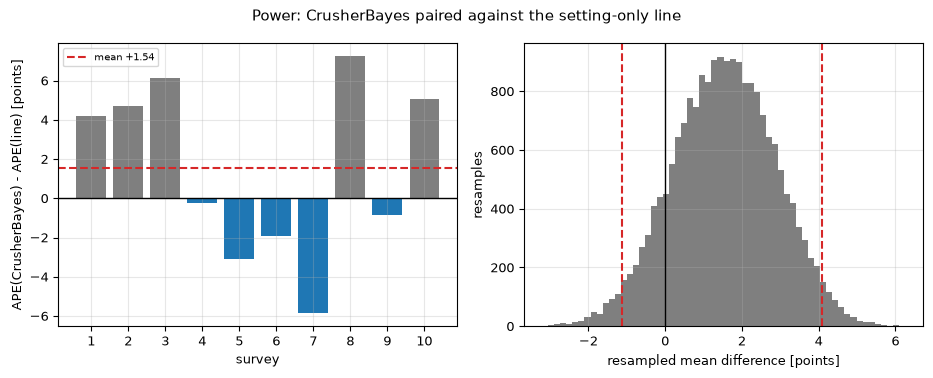

In [12]:
# The ten paired differences and the distribution of the 20,000 resampled means, with the 95 % interval
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8))
surveys_axis = np.arange(1, d.size + 1)
axes[0].bar(surveys_axis, d, color=np.where(d > 0, "tab:grey", "tab:blue"))
axes[0].axhline(0, color="black", lw=1)
axes[0].axhline(d.mean(), color="tab:red", ls="--", lw=1.5, label=f"mean {d.mean():+.2f}")
axes[0].set_xticks(surveys_axis)
axes[0].set_xlabel("survey")
axes[0].set_ylabel("APE(CrusherBayes) - APE(line) [points]")
axes[0].legend(fontsize=7)
axes[1].hist(resampled, bins=60, color="tab:grey")
for edge in (ci_lo, ci_hi):
    axes[1].axvline(edge, color="tab:red", ls="--", lw=1.5)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_xlabel("resampled mean difference [points]")
axes[1].set_ylabel("resamples")
fig.suptitle("Power: CrusherBayes paired against the setting-only line")
fig.tight_layout()
plt.show()

The left panel shows why the mean alone misleads. The line is better on surveys 1, 2, 3, 8 and 10, by 4.17 to 7.24 points, and CrusherBayes on surveys 4, 5, 6, 7 and 9 (blue), by 0.25 to 5.87 points: five wins each, and the mean of +1.54 points is the balance of two groups of large differences of opposite sign, not a small gap repeated on every survey. The right panel is the distribution of the resampled means. Its 2.5 and 97.5 percent quantiles, -1.11 and +4.10 points, are the document's interval to the fourth decimal printed (the mean differs there only because the document stores it to six decimals, 1.53685, which rounds up), and 87.0 percent of its mass lies above zero, the document's p_better. The interval contains zero, so ten surveys do not establish that the line is the better power predictor, and they establish still less that CrusherBayes is. What the figure does not show is any survey's influence on the ranking itself, which the next cells measure.

**Where it breaks with ten surveys.** Two weaknesses of the percentile interval show at this size. The first is its width: the bootstrap distribution of a mean over $n$ values has the variance of the plug-in estimate,

$$\operatorname{Var}^{*}\bigl(\bar d^{*}\bigr) = \frac{1}{n}\cdot\frac{1}{n}\sum_{i=1}^{n}\bigl(d_i - \bar d\bigr)^2 = \frac{n-1}{n}\cdot\frac{s^2}{n},$$

not $s^2/n$: each resample draws from the ten observed differences as they stand, so its spread is their plug-in variance, which divides by $n$ where the sample variance $s^2$ divides by $n-1$. The cell above prints a bootstrap standard deviation of 1.341 points against $s/\sqrt{n} = 1.417$, a ratio of 0.947 where $\sqrt{(n-1)/n} = 0.949$: at ten surveys the interval is about 5 percent narrower than a normal interval with the sample variance, and it covers less than 95 percent. It describes the spread of the resamples honestly; it is not a guaranteed 95 percent. The second weakness is the ranking: the recommended method is the minimum of a handful of means of ten numbers, and one survey can move it. The next cell drops each survey in turn, recomputes the MAPE of every method that is not a control from the document's per-survey errors, and prints the method each nine-survey set would recommend.

In [13]:
# Leave one survey out of the ranking: the method each nine-survey set recommends, from the document's errors
n_surveys = paired_doc["n"]
for name in comparison.TARGETS:
    block = paired_doc["targets"][name]
    scored = {m["id"]: np.array(m["ape_pct"]) for m in block["methods"] if not m["control"] and m["ape_pct"]}
    picks = []
    for drop in range(n_surveys):
        keep = np.delete(np.arange(n_surveys), drop)
        picks.append(min(scored, key=lambda rid: scored[rid][keep].mean()))
    counts = {rid: picks.count(rid) for rid in dict.fromkeys(picks)}
    print(f"{name}: on all ten {block['recommended']}; without survey 1 to 10: {', '.join(picks)}")
    print(f"     nine-survey sets per recommended method: {counts}")

tph: on all ten crusherbayes; without survey 1 to 10: M0_backbone, M2_freeform, M2_freeform, crusherbayes, M0_backbone, M0_backbone, crusherbayes, M0_backbone, M0_backbone, M2_freeform
     nine-survey sets per recommended method: {'M0_backbone': 5, 'M2_freeform': 3, 'crusherbayes': 2}
kW: on all ten B_lin; without survey 1 to 10: Morrell_noload, B_lin, M2_freeform, B_lin, B_lin, B_lin, B_lin, B_lin, B_lin, B_lin
     nine-survey sets per recommended method: {'Morrell_noload': 1, 'B_lin': 8, 'M2_freeform': 1}


On the power the line stays recommended in 8 of the 10 nine-survey sets: without survey 1 the Morrell model with a no-load term takes its place, and without survey 3 the free-form regression. On the throughput the ranking does not survive at all. CrusherBayes, recommended on all ten surveys, is recommended in only 2 of the 10 nine-survey sets (without survey 4 or survey 7), the backbone in 5 and the free-form regression in 3. That is what an interval of -6.06 to +6.30 points around a mean difference of +0.09 means in practice: the throughput recommendation is decided by which surveys are in the set, and the comparison view prints the interval beside the recommended method for that reason. An interval that contains zero says the ranking is not settled; it does not say the methods are equal, and more surveys could pull either ahead.

**On your own data, and when the document is absent.** `comparison.build(loo, cb, version)` takes the two documents as dictionaries, so a reader who adds surveys to `data/examples/hp500-surveys.csv` and bakes again (`python data-pipeline/run.py hp500`, then `python data-pipeline/run.py comparison`) gets the paired rows of their own surveys, and `comparison.paired(ape_method, ape_best, idx)` pairs any two vectors of per-survey errors over any resample index. Two states change what the view can show. Without the CrusherBayes document the comparison is still built, from the CrusherCal methods alone, and says so in its note. Without the comparison document, the readiness rules mark the contract missing and give the reason the App shows in place of the paired-difference callout and of the story's certainty sentence, never a number from an older bake. The cell builds the first state from the CrusherCal document and computes the second over a derived folder that does not exist, writing nothing.

In [14]:
# CrusherBayes left out: the comparison from the CrusherCal document alone; then readiness with no comparison document
without_cb = comparison.build(loo_doc, None, version)
print("note:", without_cb["crusherbayes"]["note"]["en"])
for name in comparison.TARGETS:
    print(f"{name}: recommended without CrusherBayes {without_cb['targets'][name]['recommended']}")
not_baked = ROOT / "data/derived/not-baked"
state = readiness.compute(repo_root=ROOT, derived_root=not_baked, models_dir=not_baked / "models")
row_absent = next(r for r in state["contracts"] if r["id"] == "hp500-comparison")
print(f"hp500-comparison with its document absent: {row_absent['state']}, reason: {row_absent['reason']['en']}")

note: CrusherBayes is not in this comparison: its document (hp500/crusherbayes.json) is not in this build, so only the CrusherCal methods are compared.
tph: recommended without CrusherBayes M0_backbone
kW: recommended without CrusherBayes B_lin
hp500-comparison with its document absent: missing, reason: The HP500 validation was not baked in this build.


Without CrusherBayes the throughput recommendation moves to the backbone, the runner-up above, and the power recommendation stays with the line, which CrusherBayes did not beat; the note is the sentence the comparison view prints in that case. With the document absent the contract reads missing, with the reason the HP500 validation was not baked in this build, the one every HP500 document carries when it is absent: the reader learns why there is no paired interval, and the rest of the comparison view still works from the held-out CrusherCal document. Before trusting a recommendation from a bake of your own, check three fields of its comparison document: `crusherbayes.included`, whether the methods you expect were paired; `engine_version` against the product's VERSION, since readiness calls an older document stale; and the runner-up's `ci95`, whether it contains zero.

## Evidence

**What the surveys identify.** A posterior can be as wide as its prior for a parameter the data do not constrain. The contraction, the posterior standard deviation over the prior one, measures it for the fit to all ten surveys: below about 0.5 the surveys identify the parameter, near 1 they leave it where it started. The cell lists every parameter, sorted, from the committed document.

In [15]:

# The contraction table of the fit to all ten surveys, sorted, with the identification line at 0.5
table = sorted(committed["contraction"], key=lambda row: row["contraction"])
for row in table:
    print(f"{row['name']:26s} nominal {row['nominal']:8.2f}  posterior {row['posterior_mean']:9.2f} ", end="")
    print(f"sd {row['posterior_sd']:8.3f}  contraction {row['contraction']:.2f}")


sigma_tph                  nominal    60.00  posterior    145.23 sd   39.037  contraction 0.30
sigma_kW                   nominal    15.00  posterior     38.81 sd   10.754  contraction 0.33
discrepancy_tph_f80        nominal     0.00  posterior     56.57 sd   47.627  contraction 0.34
discrepancy_tph_css        nominal     0.00  posterior    100.84 sd   48.996  contraction 0.35
discrepancy_kW_f80         nominal     0.00  posterior     -5.16 sd   13.026  contraction 0.36
discrepancy_kW_css         nominal     0.00  posterior    -57.07 sd   13.704  contraction 0.38
q_ref_tph                  nominal   647.00  posterior    646.35 sd   75.745  contraction 0.45
zeta                       nominal     1.30  posterior      1.14 sd    0.223  contraction 0.73
pn_kw                      nominal   110.00  posterior     86.35 sd   38.039  contraction 0.80
wi_kwh_t                   nominal     9.00  posterior      8.39 sd    1.294  contraction 0.85
discrepancy_tph_constant   nominal     0.00  poste

The figure draws the same table as bars, with the identification line at 0.5 and the prior at 1.

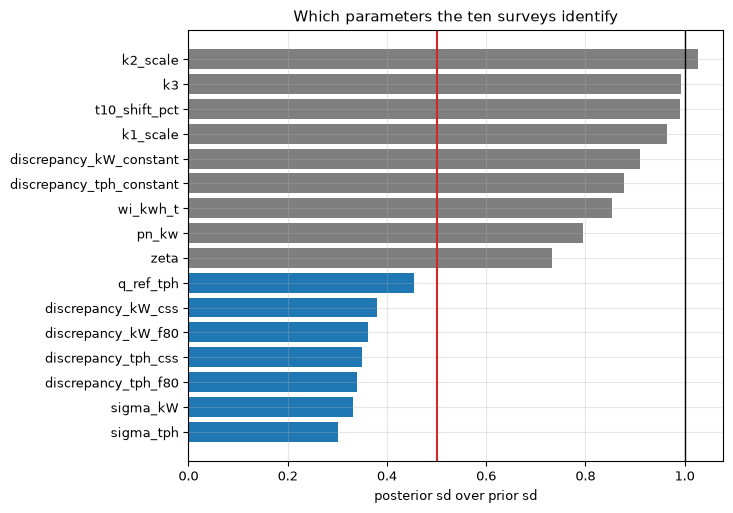

In [16]:

# Posterior over prior standard deviation of every parameter, from the document
fig, ax = plt.subplots(figsize=(7.4, 5.2))
names = [row["name"] for row in table]
values = [row["contraction"] for row in table]
ax.barh(names, values, color=["tab:blue" if v < 0.5 else "tab:grey" for v in values])
ax.axvline(0.5, color="tab:red", lw=1.5)
ax.axvline(1.0, color="black", lw=1)
ax.set_xlabel('posterior sd over prior sd')
ax.set_title('Which parameters the ten surveys identify')
fig.tight_layout()
plt.show()


7 of the 16 parameters fall below 0.5: q_ref_tph, sigma_tph, sigma_kW, discrepancy_tph_css, discrepancy_tph_f80, discrepancy_kW_css, discrepancy_kW_f80. They are the capacity base (the one scalar that moves the throughput, notebook 01), the two noise scales and the discrepancy slopes on the setting and on the feed f80. Everything else stays above 0.7, close to its prior or only slightly narrowed: `zeta` at 0.73, `wi_kwh_t` at 0.85, `pn_kw` at 0.80, and `k1_scale`, `k2_scale`, `k3` and `t10_shift_pct` at 0.96, 1.03, 0.99 and 0.99, the constants of the discrepancy at 0.91 and 0.88. The ten surveys therefore do not determine the Andersen constants K1, K2 and K3 or the t10 shift of the classification and breakage models: the posterior of those scalars is their prior, and a prediction that depends on them is carried by the discrepancy instead. This is a result about the data, not a flaw of the sampler. The figure does not show whether more surveys would identify them; it shows that these ten, which vary only the setting and the feed size, do not.

**The kill criterion.** The rule is applied with the module's own function, from the scores and interval widths computed in this notebook, term by term.

In [17]:

# The kill criterion of the SDD, evaluated with the module's function on the numbers computed above,
# rounded as the bake rounds them (MAPE and widths to two decimals, coverage to three)
verdict = cb.kill_criterion(
    power_mape=round(cb_score["kW"]["mape"], 2), power_mape_blin=round(comparator_mape["kW"]["B_lin"], 2),
    tph_mape=round(cb_score["tph"]["mape"], 2), tph_mape_m0=round(comparator_mape["tph"]["M0"], 2),
    coverage={t: round(cb_score[t]["coverage"], 3) for t in cb.TARGETS},
    width={t: round(cb_score[t]["width"], 2) for t in cb.TARGETS},
    width_crushercal={t: round(float(np.mean(cc_band[t][1] - cc_band[t][0])), 2) for t in cb.TARGETS})
v = verdict
print(f"(a) power MAPE {v['power_mape_pct']:.2f} % against the setting-only line {v['power_mape_blin_pct']:.2f} %: "
      f"gain {v['power_gain_over_blin_pts']:+.2f} points, 3.0 needed, "
      f"beats by the margin: {v['a_power_beats_blin_by_margin']}")
print(f"(a) throughput MAPE {v['tph_mape_pct']:.2f} % against the backbone {v['tph_mape_m0_pct']:.2f} %: "
      f"gain {v['tph_gain_over_m0_pts']:+.2f} points, beats by the margin: {v['a_tph_beats_m0_by_margin']}")
print(f"(a) holds, that is neither beats its comparator by the margin: {v['a_holds']}")
print(f"(b) coverage {v['coverage']}, outside 0.7 to 0.9: {v['coverage_outside_band']}")
print(f"(b) band wider than CrusherCal's: {v['band_wider_than_crushercal']}, so (b) holds: {v['b_holds']}")
print(f"verdict: {v['verdict']}")


(a) power MAPE 14.31 % against the setting-only line 12.78 %: gain -1.53 points, 3.0 needed, beats by the margin: False
(a) throughput MAPE 12.00 % against the backbone 12.09 %: gain +0.09 points, beats by the margin: False
(a) holds, that is neither beats its comparator by the margin: True
(b) coverage {'tph': 0.8, 'kW': 0.9}, outside 0.7 to 0.9: {'tph': False, 'kW': False}
(b) band wider than CrusherCal's: {'tph': False, 'kW': False}, so (b) holds: False
verdict: kept


Part (a) of the rule holds: the power gain over the setting-only line is -1.53 points, negative, where 9.78 percent (the setting-only line's 12.78 less the margin) would have been needed, and the throughput gain over the backbone is +0.09 points against the 3 required. Part (b) does not hold: both coverages lie inside 0.7 to 0.9 and both bands are narrower than CrusherCal's. The rule drops the method only when (a) and (b) both hold, so the verdict is **kept**: CrusherBayes stays in the product as a predictor because its interval is narrower than the CrusherCal band with a coverage inside 0.7 to 0.9, although it does not beat the setting-only line on the power and its interval is about as wide as the setting-only line's band (117.7 against 119.6 kW). The verdict rests on part (b) alone, and on its edge: the power coverage of 0.9 sits on the inclusive upper bound of 0.7 to 0.9, so one more survey of ten inside the power interval would give 1.0, outside the band, (b) would hold and the method would be dropped. The criterion also says that even then the identifiability table is the result, and that is the section above. The one reproduction check of the notebook follows: the scores, the power gain and the verdict recomputed here against the committed document, and the paired power interval of CrusherBayes against the setting-only line, recomputed in the Comparison section, against the comparison document.

In [18]:

# The one reproduction check: the scores, the power gain and the verdict recomputed here against the
# committed document, and the paired power interval against the comparison document
doc_kc = committed["kill_criterion"]
scores_equal = all(abs(cb_score[t]["mape"] - committed["loo"][t]["scores"]["mape_pct"]) < 0.01 for t in cb.TARGETS)
gain_equal = verdict["power_gain_over_blin_pts"] == doc_kc["power_gain_over_blin_pts"]
paired_equal = [round(float(v), 6) for v in (d.mean(), ci_lo, ci_hi)] == [row_cb["mean_diff_pts"], *row_cb["ci95"]]
print(f"scores equal the document: {scores_equal} | power gain equals the document's "
      f"({doc_kc['power_gain_over_blin_pts']:+.2f}): {gain_equal} | verdict equals the document's "
      f"({doc_kc['verdict']}): {verdict['verdict'] == doc_kc['verdict']} | paired power interval equals "
      f"the comparison document's: {paired_equal}")


scores equal the document: True | power gain equals the document's (-1.53): True | verdict equals the document's (kept): True | paired power interval equals the comparison document's: True


**What the convergence record shows.** The committed chains are the longest the bake runs, and the document records for each posterior whether the sampler passed its own diagnostic, a chain of at least 50 autocorrelation times. The cell prints that record.

In [19]:

# The convergence record of the committed chains
print('posterior   tau [steps]   chain over tau   converged')
for row in record:
    print(f"{row['fold']!s:9s} {row['tau_max']:12.1f} {row['chain_over_tau']:16.1f} {row['converged']!s:>11}")


posterior   tau [steps]   chain over tau   converged
1                 52.6            114.1        True
2                 52.7            113.8        True
3                 54.7            109.7        True
4                 84.8             70.7        True
5                 52.7            113.9        True
6                 48.0            125.0        True
7                 55.1            108.9        True
8                 48.9            122.7        True
9                 52.6            114.1        True
10                50.7            118.3        True
all               48.6            123.5        True


11 of the 11 posteriors pass: the chains of 7000 steps have autocorrelation times of 48 to 85 steps and lengths of 70.7 to 125.0 times that, above the 50 the pipeline requires, with the differential-evolution moves of ter Braak (2006) and ter Braak and Vrugt (2008) that the sampler uses (an earlier bake with the stretch move of Goodman and Weare (2010) did not reach it). The scores above are therefore estimates from chains that passed the sampler's own diagnostic. That is a statement about the chains and not a proof of convergence: the diagnostic is one criterion, and ten surveys leave the weakly identified parameters wide whatever the chain length, so the contraction ratios near 1 mean the data do not constrain them, not that the sampler failed.

### Sensitivity of the comparison to the ten surveys: the uncertainty of the two gains

The verdict rests on two differences of errors measured on ten surveys, $\Delta_P = -1.53$ and $\Delta_Q = +0.09$ points, and a difference measured on ten points has its own uncertainty, which the point values hide. The cell estimates it by the bootstrap over surveys: it resamples the ten surveys with replacement 4000 times, with a fixed seed, recomputes both gains on each resample from the held-out predictions already in hand (no refit, so this is the uncertainty of the comparison given the predictions, not of the fits), and reports the 80 and 95 percent intervals and the share of resamples in which each gain reaches the 3-point margin.

kW   gain over the setting-only line: 80 % [-3.26, +0.19] | 95 % [-4.13, +1.07] points | share at or above 3 points: 0.000
tph  gain over the backbone: 80 % [-3.98, +4.40] | 95 % [-6.12, +6.52] points | share at or above 3 points: 0.183


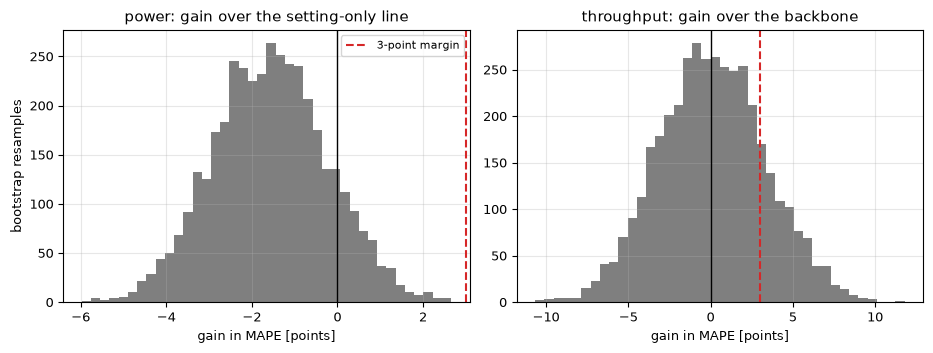

In [20]:
# Bootstrap over the ten surveys of the power gain over the setting-only line and of the throughput gain over the
# backbone
rng = np.random.default_rng(2026)
y = {t: np.array(committed["loo"][t]["measured"]) for t in cb.TARGETS}
cb_pred = {t: np.array(committed["loo"][t]["pred_mean"]) for t in cb.TARGETS}
ref_pred = {"kW": np.array(crushercal["loo"]["kW"]["strict"]["pred"]["B_lin"]),
            "tph": np.array(crushercal["loo"]["tph"]["strict"]["pred"]["M0"])}
gains = {t: [] for t in cb.TARGETS}
for _ in range(4000):
    pick = rng.integers(0, 10, 10)
    for t in cb.TARGETS:
        gains[t].append(loo.mape(y[t][pick], ref_pred[t][pick]) - loo.mape(y[t][pick], cb_pred[t][pick]))
for t, against in (("kW", "the setting-only line"), ("tph", "the backbone")):
    g = np.array(gains[t])
    lo80, hi80, lo95, hi95 = np.percentile(g, [10, 90, 2.5, 97.5])
    print(f"{t:4s} gain over {against}: 80 % [{lo80:+.2f}, {hi80:+.2f}] | 95 % [{lo95:+.2f}, {hi95:+.2f}] points",
          f"| share at or above 3 points: {np.mean(g >= 3):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))
panels = ((axes[0], "kW", "power: gain over the setting-only line"),
          (axes[1], "tph", "throughput: gain over the backbone"))
for ax, t, title in panels:
    ax.hist(gains[t], bins=40, color="tab:grey")
    ax.axvline(0, color="black", lw=1)
    ax.axvline(3, color="tab:red", ls="--", lw=1.5, label="3-point margin")
    ax.set_xlabel("gain in MAPE [points]")
    ax.set_title(title)
axes[0].set_ylabel("bootstrap resamples")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

Both intervals straddle zero, so on ten surveys neither sign is established: the power gain over the setting-only line could be a loss of several points or a small gain, and the throughput gain over the backbone is centred near zero with a spread of a few points either way. None of the power resamples and 18.3 percent of the throughput resamples reach the 3-point margin, so part (a) of the rule would hold in most resamples, as it does on the observed ten. This is the uncertainty the point values of the comparison carry, and it is wider than the differences themselves; it is also a lower bound, since it holds the predictions fixed and a refit on the resampled surveys would add the variation of the fits. The reading the product draws is the one the margin was written for: a method that does not clear 3 points on ten surveys has not shown an accuracy gain, whatever the sign of its point estimate, and the negative result on the power is reported as a negative, not as a tie.

### Using it on your own data: the kill criterion on the scores of your own calibration

The rule takes numbers, not documents, so a reader who calibrates a table of their own (notebook 02) and scores it held out, as this notebook does, applies it with one call. The cell shows the call twice with typed-in scores that are not results of any calibration, only inputs chosen to show the two outcomes: a calibration whose power error is 4 points below the setting-only line's, which part (a) keeps whatever its intervals, and one with no accuracy gain and a power coverage of 0.6, outside the window, which the rule drops. It also prints the fields of the held-out block of the committed document, `loo`, which is where a reader's own run of `cb.build` would put the same numbers (contract `hp500-crusherbayes`).

In [21]:
# The kill criterion on two sets of typed-in scores (inputs to show the call), then the document's loo fields
cases = {"wins on power by 4 points": dict(power_mape=8.78, tph_mape=12.0, coverage={"tph": 0.8, "kW": 0.8}),
         "no gain, power coverage 0.6": dict(power_mape=13.5, tph_mape=12.0, coverage={"tph": 0.8, "kW": 0.6})}
for label, scores in cases.items():
    outcome = cb.kill_criterion(power_mape_blin=12.78, tph_mape_m0=12.09, width={"tph": 430.0, "kW": 115.0},
                                width_crushercal={"tph": 473.8, "kW": 209.8}, **scores)
    print(f"{label:28s} (a) {outcome['a_holds']!s:5s} (b) {outcome['b_holds']!s:5s} -> {outcome['verdict']}")
print("fields of the committed loo block, power:", sorted(committed["loo"]["kW"]))

wins on power by 4 points    (a) False (b) False -> kept
no gain, power coverage 0.6  (a) True  (b) True  -> dropped as a predictor
fields of the committed loo block, power: ['hi80', 'lo80', 'measured', 'pred_mean', 'scores']


The first set is kept by part (a) alone: a power gain of 4 points over the setting-only line clears the margin, so the method stays whatever its intervals do. The second is dropped: no accuracy gain on either target makes (a) hold, and a power coverage of 0.6, outside 0.7 to 0.9, makes (b) hold too. The committed method sits between them, kept by (b) failing to hold, since its intervals are calibrated within the window and narrower than CrusherCal's, while (a) holds. A reader who runs the calibration on another machine should fix their own margin and window before looking at the scores, as the design document fixed these, and should read the held-out block of their own document, the prediction and the interval of every survey and the scores built from them, before the verdict, because the verdict compresses exactly the uncertainty that the bootstrap above showed.

## Results

**Answer:** CrusherBayes does not predict a held-out survey better than the setting-only line; it does give a narrower interval than the CrusherCal band with a coverage inside 0.7 to 0.9, and the criterion keeps it. Held out on the ten surveys it has a power error of 14.31 percent against 12.78 for the setting-only line (1.53 points behind) and 25.94 for the backbone, and a throughput error of 12.00 percent against 12.09 for the backbone, a gain of 0.09 points that ten surveys cannot tell from zero. Its 80 percent intervals are 118 kW and 439 t/h wide against 210 kW and 474 t/h for CrusherCal, with 9 and 8 surveys of 10 inside. That is a gain over the backbone's band, not over a line: the setting-only line's nested band on the power is already 119.6 kW wide at coverage 0.8, against 117.7 kW at coverage 0.9 for CrusherBayes, one survey of ten apart. The surveys identify the capacity base (contraction 0.45), the noise and the discrepancy slopes, and leave K1, K2, K3 and the t10 shift at their prior (contraction 0.96 to 1.03). The kill criterion, recomputed here from the notebook's own numbers, gives the verdict kept that the document records, because part (b) does not hold, and only just: the power coverage of 0.9 sits on the edge of 0.7 to 0.9. The chains passed their own diagnostic in 11 of 11 posteriors, at 70.7 to 125.0 autocorrelation times. The product's paired comparison (contract `hp500-comparison`) recommends CrusherBayes on the throughput and the setting-only line on the power; CrusherBayes trails the line on the power by +1.54 points with a 95 percent interval of -1.11 to +4.10, recomputed here from the held-out predictions, and on the throughput its recommendation holds in only 2 of the 10 nine-survey sets.

## Summary

CrusherBayes is measured here against the criterion that was written before it ran. It narrows the backbone's predictive interval on the power from 210 to 118 kW and cuts the backbone's power error from 25.94 to 14.31 percent, but the simplest competitor, a line on the setting, predicts the power as well or better (12.78 percent) and already gives a band about as narrow (119.6 kW at coverage 0.8), and the method does not claim otherwise. What it adds that no point fit gives is the identifiability table: with ten surveys of one machine the data say what the capacity and the noise are and say nothing about the classification and breakage constants. The result stands on chains that passed their convergence diagnostic in all eleven posteriors, so the contraction ratios can be quoted as measured, within what ten surveys can show.

On ten surveys the bootstrap intervals of both gains straddle zero and seldom reach the margin, and the rule that weighs them takes a reader's own scores in one call. The paired comparison says the same survey by survey: five wins each for CrusherBayes and the line on the power, and a throughput recommendation that dropping one survey changes in 8 of 10 cases.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- ter Braak, C. J. F. (2006), A Markov chain Monte Carlo version of the genetic algorithm differential evolution: easy Bayesian computing for real parameter spaces, Statistics and Computing 16, 239-249. https://doi.org/10.1007/s11222-006-8769-1
- ter Braak, C. J. F., Vrugt, J. A. (2008), Differential evolution Markov chain with snooker updater and fewer chains, Statistics and Computing 18, 435-446. https://doi.org/10.1007/s11222-008-9104-9
- Goodman, J., Weare, J. (2010), Ensemble samplers with affine invariance, Communications in Applied Mathematics and Computational Science 5(1), 65-80. https://doi.org/10.2140/camcos.2010.5.65
- Hyndman, R. J., Koehler, A. B. (2006), Another look at measures of forecast accuracy, International Journal of Forecasting 22(4), 679-688. https://doi.org/10.1016/j.ijforecast.2006.03.001